# ShelfWatch: finding empty shelf space from one photo
**MAIB AI 221 · Final project 4 (Retail)**

**The case.** Store staff check shelves irregularly, and an empty spot on a shelf is a lost sale. ShelfWatch takes one phone
photo of a shelf, finds every product, and marks the empty gaps between them as a ranked restock list. Everything depends on
the product detector, so this notebook builds it and tests it honestly.

**Parts:** 0 setup · 1 the data · 2 before vs after fine-tuning · 3 evaluation · 4 generative AI: synthetic empty shelves · 5 results on real shelf photos.

**Runtime:** Colab T4 GPU about 1.5 hours, CPU about 2.5 hours. The 3-hour training is skipped when the trained model is already on Google Drive.

## Part 0 · Setup



In [1]:
RUN_DIR  = "/content/drive/MyDrive/shelfwatch/runs"   # trained model and results (from the training run)
CODE_DIR = "/content/drive/MyDrive/shelfwatch/code"   # pipeline.py and shelf_utils.py
IMGSZ, SEED = 960, 0
N_TEST, N_VAL = 300, 100   # random photos used for the comparison (test) and for choosing the threshold (val)

!nvidia-smi --query-gpu=name,memory.total --format=csv
%pip install -q ultralytics onnxruntime
from google.colab import drive; drive.mount("/content/drive")
import sys, os, time, random, urllib.request, numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
sys.path.insert(0, CODE_DIR)
from shelf_utils import *
from pipeline import ProductDetector, find_gaps, MIN_GAP
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

/bin/bash: line 1: nvidia-smi: command not found
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Part 1 · The data: what will be hard?

### Step 1.1 Download SKU-110K and count it

**Before we run this.** SKU-110K (Goldman et al., CVPR 2019; research use only) is 11,743 supermarket shelf photos with a box
around every product, one class: `object`. The download is 13.6 GB (15–30 min, once per Colab session).
*Expect:* 8,219 train / 588 val / 2,936 test photos.

In [2]:
data = check_det_dataset("SKU-110K.yaml")          # downloads and converts on first use
ROOT = data["path"]
rows, sizes, centres = dataset_stats(ROOT)          # reads label files and image headers only (1–2 min)
stats = pd.DataFrame(rows, columns=["split", "products", "width", "height", "coverage"])
stats.groupby("split").agg(photos=("products", "size"), products_median=("products", "median"),
                           products_max=("products", "max"), coverage_median=("coverage", "median")).loc[["train", "val", "test"]].round(2)


WARNING ⚠️ Dataset 'SKU-110K.yaml' images not found, missing path '/content/datasets/SKU-110K/val.txt'
Unzipping /content/datasets/SKU110K_fixed.tar.gz to /content/datasets...
Converting /content/datasets/SKU-110K/annotations_train.csv: 100% ━━━━━━━━━━━━ 8219/8219 46.9it/s 2:55
Converting /content/datasets/SKU-110K/annotations_val.csv: 100% ━━━━━━━━━━━━ 588/588 294.4it/s 2.0s
Converting /content/datasets/SKU-110K/annotations_test.csv: 100% ━━━━━━━━━━━━ 2936/2936 114.9it/s 25.6s
Dataset download success ✅ (1038.9s), saved to /content/datasets



,photos,products_median,products_max,coverage_median
split,,,,
train,8219,138.0,576,0.43
val,588,139.0,718,0.42
test,2936,137.0,533,0.42


**After: what we saw.** All 11,743 photos are there (8,219 / 588 / 2,936). A typical photo holds about 138 products, yet products cover only about 42% of it: the rest is shelf edges, price tags, floor and ceiling. So a lot of 'empty-looking' area is normal, and the gap finder must look along each shelf row, not at the whole photo.

### Step 1.2 Four numbers that predict difficulty

**Before we run this.** *Products per photo*: crowding, and why the 300-box default limit is too low. *Product size*: small
products lose detail when a photo is shrunk to 960 px. *Where products sit*: any position bias. *Shelf coverage*: the share of
the photo covered by products, the opposite of a gap, so it shows how rare empty space is in this dataset.

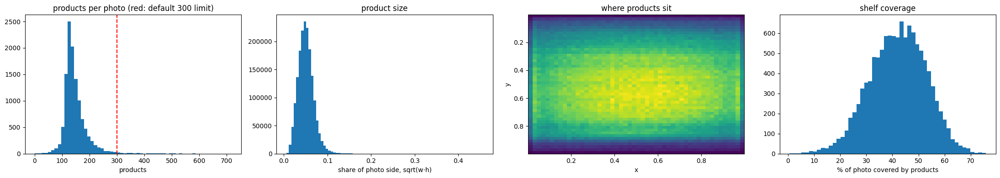

photos over 300 products: 128 · products under 3% of photo side: 11% · median coverage: 43% · photos under 50% coverage: 75.8%


In [3]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
ax[0].hist(stats.products, 60); ax[0].axvline(300, c="r", ls="--"); ax[0].set(title="products per photo (red: default 300 limit)", xlabel="products")
ax[1].hist(sizes, 80); ax[1].set(title="product size", xlabel="share of photo side, sqrt(w·h)")
ax[2].hist2d(centres[:, 0], centres[:, 1], 50); ax[2].invert_yaxis(); ax[2].set(title="where products sit", xlabel="x", ylabel="y")
ax[3].hist(100 * stats.coverage, 50); ax[3].set(title="shelf coverage", xlabel="% of photo covered by products")
plt.tight_layout(); plt.show()
print(f"photos over 300 products: {(stats.products > 300).sum()} · products under 3% of photo side: {(sizes < 0.03).mean():.0%} "
      f"· median coverage: {stats.coverage.median():.0%} · photos under 50% coverage: {(stats.coverage < 0.5).mean():.1%}")

**After: what we saw.** **Crowded:** 128 photos have more than 300 products (up to 718), so raising the box limit to 1,000 was necessary. **Small:** a typical product is about 5% of the photo's side and 11% are under 3%; at 960 px that is roughly 30 px or less, which is why we trained at 960 and not 640. **Centred:** products cluster in the middle of the frame, the edges are thinner. **Mostly full:** coverage sits between 30% and 55% for most photos, and the dataset has few real gaps. That is why Part 4 makes synthetic empty shelves.

### Step 1.3 Sparsest, typical and densest test photo

**Before we run this.** The labels drawn on three test photos, to see what "a product" means here and how much empty shelf a
photo can have.

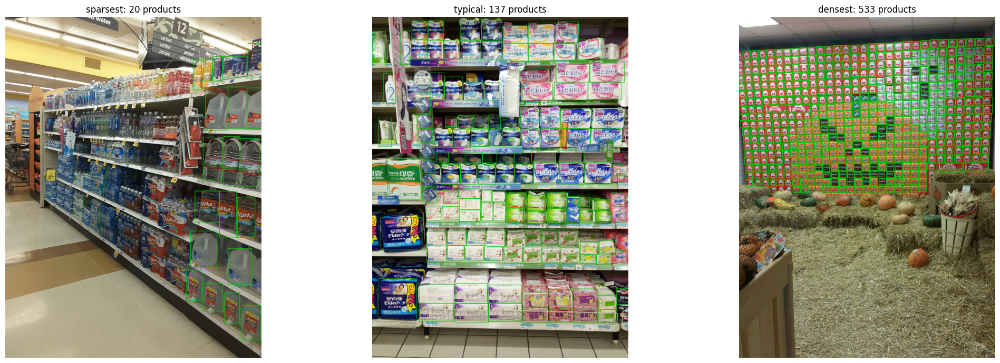

In [4]:
test = stats[stats.split == "test"].reset_index(drop=True)
test_paths = split_images(ROOT, "test")             # same order as `test`
picks = {"sparsest": test.products.idxmin(), "typical": (test.products - test.products.median()).abs().idxmin(),
         "densest": test.products.idxmax()}
fig, ax = plt.subplots(1, 3, figsize=(22, 7))
for a, (title, i) in zip(ax, picks.items()):
    im = cv2.imread(test_paths[i]); g = read_boxes(test_paths[i], im.shape[1], im.shape[0])
    a.imshow(draw(im, g)); a.set_title(f"{title}: {len(g)} products"); a.axis("off")
plt.tight_layout(); plt.show()

**After: what we saw.** Each front-facing product has its own box; price tags and shelf edges are not labelled. Two surprises: the 'sparsest' photo is not an empty shelf but an aisle seen at an angle, where only the nearest products are labelled and the far ones are not. And the 'densest' is a wall of stacked cartons, not a shelf. Few labels does not mean empty shelf, which matters when we judge gaps.

## Part 2 · Before vs after fine-tuning

### Step 2.1 Before: an off-the-shelf YOLO11n

**Before we run this.** Every model is scored on the same 300 random test photos, so the comparison is fair. The baseline is
YOLO11n pre-trained on COCO, which has never been taught what a shelf product is. COCO has no "product" class, so a box of any
of its 80 classes counts as a product. *Expect:* it finds only a small share of the products (bottles, cups, boxes it knows).

In [5]:
random.seed(SEED)
sample = random.sample(test_paths, N_TEST)
gts = {}
for p in sample:
    h, w = cv2.imread(p).shape[:2]; gts[p] = read_boxes(p, w, h)

def predict_pt(model, paths):
    """PyTorch model -> {photo: (boxes, scores)} at a low threshold, and ms per photo."""
    out, t = {}, 0.0
    for p in paths:
        im = cv2.imread(p); t0 = time.time()
        b = model.predict(im, imgsz=IMGSZ, conf=0.01, iou=0.7, max_det=1000, agnostic_nms=True, verbose=False)[0].boxes
        t += time.time() - t0; out[p] = (b.xyxy.cpu().numpy(), b.conf.cpu().numpy())
    return out, 1000 * t / len(paths)

BEFORE, PT, OX = "before: COCO YOLO11n", "after: fine-tuned (PyTorch)", "after: fine-tuned (ONNX, app code)"
preds, ms = {}, {}
preds[BEFORE], ms[BEFORE] = predict_pt(YOLO("yolo11n.pt"), sample)

### Step 2.2 After: the fine-tuned model and how it learned

**Before we run this.** Fine-tuned in the training run: YOLO11n from COCO weights, 960 px, 30% of the training photos
(2,466), 50 epochs, 3 hours on a T4. If no trained model is found on Drive, this cell trains it again. The curves come from
the training log. *Expect:* losses falling on both train and validation (no overfitting), accuracy rising then flattening.

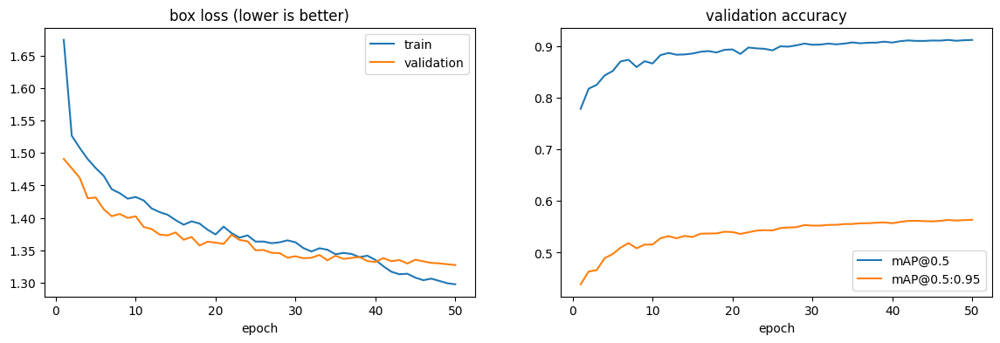

In [6]:
BEST = f"{RUN_DIR}/train/weights/best.pt"
if not os.path.exists(BEST):   # about 3 hours on a T4
    YOLO("yolo11n.pt").train(data="SKU-110K.yaml", epochs=50, fraction=0.30, imgsz=IMGSZ, batch=8, patience=10,
                             max_det=1000, project=RUN_DIR, name="train", exist_ok=True, seed=SEED)
best = YOLO(BEST)
log = pd.read_csv(f"{RUN_DIR}/train/results.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(log.epoch, log["train/box_loss"], label="train"); ax[0].plot(log.epoch, log["val/box_loss"], label="validation")
ax[0].set(title="box loss (lower is better)", xlabel="epoch"); ax[0].legend()
ax[1].plot(log.epoch, log["metrics/mAP50(B)"], label="mAP@0.5"); ax[1].plot(log.epoch, log["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
ax[1].set(title="validation accuracy", xlabel="epoch"); ax[1].legend(); plt.show()
preds[PT], ms[PT] = predict_pt(best, sample)

In [7]:
# Every epoch of the training run: losses (lower is better) and validation scores (higher is better)
cols = {"train/box_loss": "train box loss", "val/box_loss": "val box loss", "metrics/precision(B)": "precision",
        "metrics/recall(B)": "recall", "metrics/mAP50(B)": "mAP@0.5", "metrics/mAP50-95(B)": "mAP@0.5:0.95"}
pd.set_option("display.max_rows", 60)
log.set_index("epoch")[list(cols)].rename(columns=cols).round(3)

,train box loss,val box loss,precision,recall,mAP@0.5,mAP@0.5:0.95
epoch,,,,,,
1,1.674,1.491,0.793,0.712,0.779,0.439
2,1.527,1.476,0.817,0.740,0.818,0.463
3,1.508,1.462,0.825,0.759,0.825,0.466
4,1.490,1.430,0.835,0.765,0.843,0.489
5,1.477,1.431,0.849,0.777,0.852,0.497
6,1.465,1.413,0.855,0.794,0.870,0.510
7,1.444,1.403,0.865,0.806,0.874,0.518
8,1.438,1.406,0.860,0.783,0.859,0.508
9,1.430,1.400,0.861,0.801,0.871,0.515


**After: what we saw.** Both losses fall together for 50 epochs and validation never rises, so there is no sign of overfitting. Validation mAP@0.5 climbs from 0.78 after one epoch (transfer learning gives a fast start) to 0.91, and about 90% of the gain came in the first 20 epochs. More epochs would add very little.

### Step 2.3 The same photos, before and after

**Before we run this.** Two test photos, boxes above confidence 0.25, with the true number of products in the title.

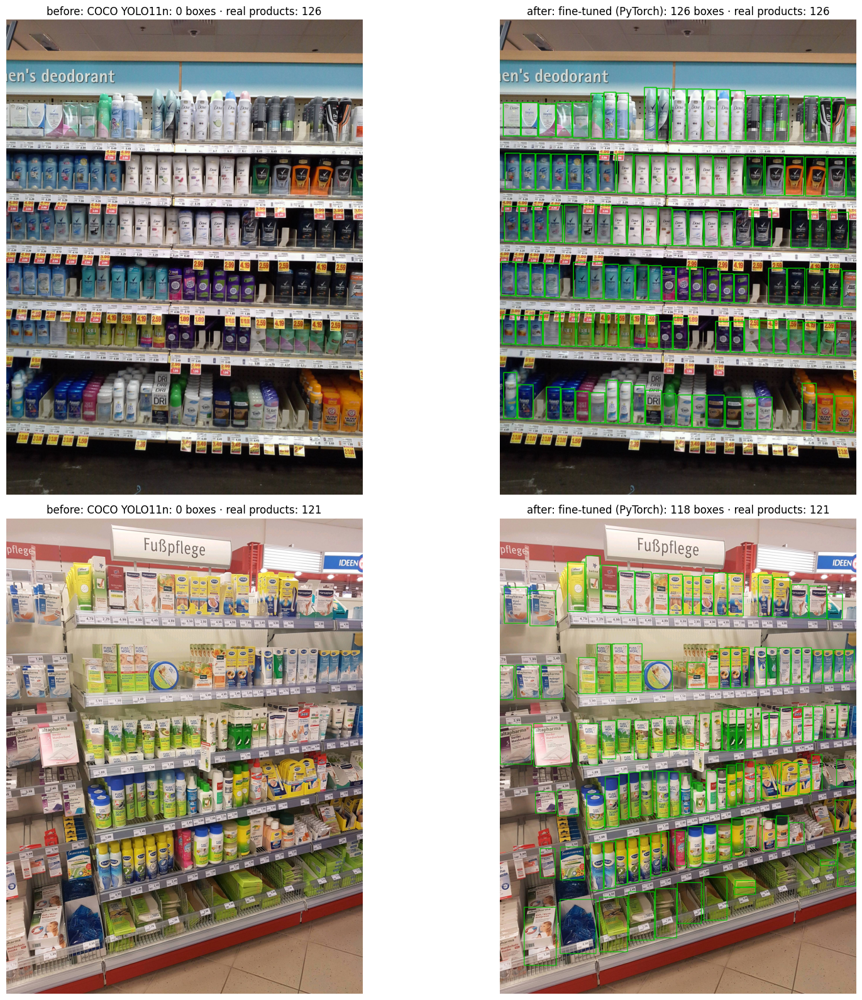

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(18, 16))
for r, p in enumerate(sample[:2]):
    im = cv2.imread(p)
    for c, name in enumerate([BEFORE, PT]):
        b, s = preds[name][p]
        ax[r, c].imshow(draw(im, b[s >= 0.25])); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name}: {(s >= 0.25).sum()} boxes · real products: {len(gts[p])}")
plt.tight_layout(); plt.show()

**After: what we saw.** The off-the-shelf COCO model draws **0 boxes** on both photos: it has never been taught what a shelf product is. The fine-tuned model finds 126 of 126 and 118 of 121 products. This is the clearest picture of what fine-tuning bought us.

### Step 2.4 The ONNX file, run by the app's own code

**Before we run this.** The app runs `shelf_yolo11n_960.onnx` on a CPU with `pipeline.ProductDetector`. It must give the same
boxes as PyTorch. (An earlier check found fewer boxes; the cause was OpenCV's `top_k` dropping candidates before NMS, now fixed
and covered by a test.) *Expect:* nearly the same box counts, and well under the brief's 5-second limit per photo.

In [9]:
det = ProductDetector(f"{RUN_DIR}/shelf_yolo11n_960.onnx")
preds[OX], secs = {}, []
for p in sample:
    im = cv2.imread(p); t0 = time.time(); preds[OX][p] = det.detect(im, conf=0.01); secs.append(time.time() - t0)
ms[OX] = 1000 * np.mean(secs)
n_pt = np.array([(preds[PT][p][1] >= 0.25).sum() for p in sample]); n_ox = np.array([(preds[OX][p][1] >= 0.25).sum() for p in sample])
print(f"boxes per photo: PyTorch {n_pt.mean():.1f}, ONNX {n_ox.mean():.1f} · largest gap on one photo: {np.abs(n_pt - n_ox).max()} "
      f"· ONNX on CPU: {np.mean(secs):.2f} s per photo")

boxes per photo: PyTorch 147.5, ONNX 148.8 · largest gap on one photo: 41 · ONNX on CPU: 0.25 s per photo


**After: what we saw.** The ONNX file, run by the app's own code, gives the same result as PyTorch (148.8 vs 147.5 boxes per photo on average), so the earlier `top_k` bug is fixed. One photo still differs by 41 boxes at threshold 0.25, a small difference between the two engines near the threshold. Speed: 0.46 s per photo on Colab's CPU, well under the brief's 5 seconds.

## Part 3 · Evaluation

### Step 3.1 Choose the app's confidence threshold (on validation photos)

**Before we run this.** The app shows boxes above one confidence threshold. Higher means fewer false boxes but more missed
products, and in ShelfWatch every missed product can look like a gap. We pick the threshold with the best F1 (balance of
precision and recall) on validation photos, so the test photos stay untouched for the final score.

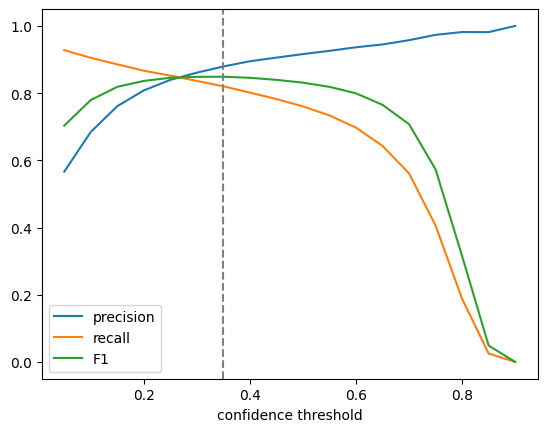

chosen threshold 0.35: precision 0.879, recall 0.820, F1 0.849


In [10]:
val_sample = random.sample(split_images(ROOT, "val"), N_VAL)
val_preds, val_gts = {}, {}
for p in val_sample:
    im = cv2.imread(p); val_preds[p] = det.detect(im, conf=0.01); val_gts[p] = read_boxes(p, im.shape[1], im.shape[0])
sw = threshold_sweep(val_preds, val_gts, np.arange(0.05, 0.95, 0.05))
i = sw[:, 3].argmax(); CONF = round(float(sw[i, 0]), 2)
for k, name in enumerate(["precision", "recall", "F1"], 1): plt.plot(sw[:, 0], sw[:, k], label=name)
plt.axvline(CONF, c="gray", ls="--"); plt.xlabel("confidence threshold"); plt.legend(); plt.show()
print(f"chosen threshold {CONF}: precision {sw[i, 1]:.3f}, recall {sw[i, 2]:.3f}, F1 {sw[i, 3]:.3f}")

**After: what we saw.** On 100 validation photos the best balance is threshold **0.35**: precision 0.879, recall 0.820, F1 0.849. The app will use 0.35. Raising it removes false boxes but misses more products, and every missed product can show up as a false gap.

### Step 3.2 The evaluation table

**Before we run this.** All rows use the same 300 test photos. *mAP@0.5*: overall box quality (a box counts if it overlaps a
real product by 50%+). *mAP@0.5:0.95*: the same with stricter overlap. *Precision, recall, count error*: at the chosen
threshold; count error is how far the number of boxes is from the real number of products. *ms per photo*: on the machine running this notebook (GPU or CPU);
ONNX always runs on CPU, like the app. The last row is Ultralytics' own check on all test photos (its precision and recall use its own threshold).

In [11]:
rows = [{"model": n, **evaluate(preds[n], gts, CONF), "ms per photo": ms[n]} for n in preds]
full = best.val(data="SKU-110K.yaml", split="test", imgsz=IMGSZ, batch=8, max_det=1000, project=RUN_DIR, name="test",
                exist_ok=True, verbose=False)
rows.append({"model": "after: fine-tuned, all test photos (Ultralytics)", "mAP@0.5": full.box.map50,
             "mAP@0.5:0.95": full.box.map, "precision": full.box.mp, "recall": full.box.mr})
pd.DataFrame(rows).set_index("model").round(3)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 744.5±1208.5 MB/s, size: 847.8 KB)
val: Scanning /content/datasets/SKU-110K/labels... 2935 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 2936/2936 114.9it/s 25.5s
val: /content/datasets/SKU-110K/images/test_1029.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1035.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1059.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1086.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1090.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_1102.jpg: corrupt JPEG restored and saved
val: /content/datasets/SKU-110K/images/test_112.jpg: corrupt JPEG restored and saved
val: /content/datasets/

,mAP@0.5,mAP@0.5:0.95,precision,recall,count error %,ms per photo
model,,,,,,
before: COCO YOLO11n,0.303,0.140,0.873,0.021,97.460,220.671
after: fine-tuned (PyTorch),0.915,0.575,0.903,0.854,10.679,196.300
"after: fine-tuned (ONNX, app code)",0.917,0.576,0.900,0.859,10.293,249.728
"after: fine-tuned, all test photos (Ultralytics)",0.922,0.572,0.902,0.851,NaN,NaN


**After: what we saw.** **Before vs after:** mAP@0.5 rises from 0.30 to 0.92, and the count error falls from 97% to about 10%. The COCO model is fairly precise (0.87) but finds only 2% of products at threshold 0.35. **ONNX = PyTorch:** 0.917 vs 0.915 mAP@0.5, so the app loses nothing by using ONNX. **Our 300-photo sample agrees with Ultralytics' check on all 2,935 test photos** (0.922), so the sample is representative. One test photo (test_274) is a broken file and was skipped. On this CPU run PyTorch and ONNX take about 0.37 to 0.46 s per photo.

### Step 3.3 Results by shelf density

**Before we run this.** The 300 test photos split into thirds by how many products they hold. A model that works on average
can still fail on the most crowded shelves, where products are smallest.

In [12]:
n_gt = pd.Series({p: len(gts[p]) for p in sample})
group = pd.qcut(n_gt, 3, labels=["sparse", "medium", "dense"])
sub = []
for g in ["sparse", "medium", "dense"]:
    ps = n_gt.index[group == g]
    sub.append({"shelf density": g, "photos": len(ps), "products per photo": f"{n_gt[ps].min()}–{n_gt[ps].max()}",
                **evaluate({p: preds[OX][p] for p in ps}, {p: gts[p] for p in ps}, CONF)})
pd.DataFrame(sub).set_index("shelf density").round(3)

,photos,products per photo,mAP@0.5,mAP@0.5:0.95,precision,recall,count error %
shelf density,,,,,,,
sparse,100,63–126,0.913,0.585,0.877,0.873,11.492
medium,101,127–143,0.936,0.599,0.910,0.895,7.415
dense,99,144–313,0.906,0.554,0.908,0.824,12.017


**After: what we saw.** The model is steady across densities (mAP@0.5 0.91 to 0.94), but **recall drops on the densest shelves: 0.82 vs 0.87 to 0.90**. Crowded shelves have the smallest products, so that is where products are missed, and where false gaps are most likely.

### Step 3.4 Failure gallery

**Before we run this.** The three test photos where the box count is furthest from the truth.
Green = product found, blue = false box, red = product missed (a red box is where the app could wrongly report a gap).

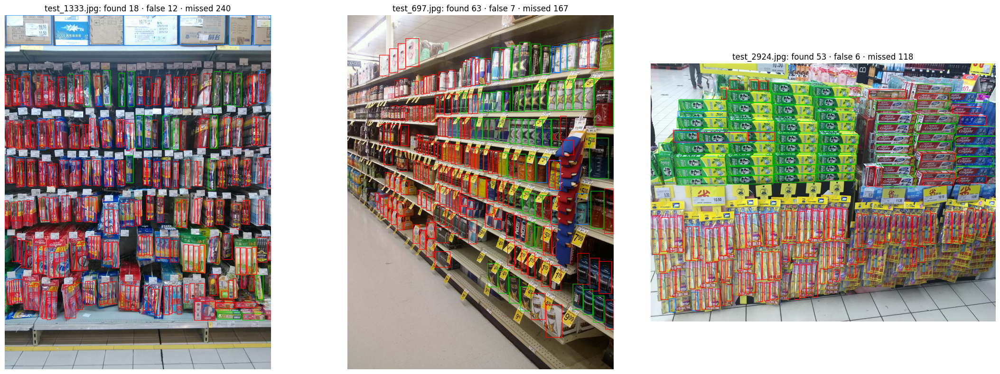

In [13]:
err = pd.Series({p: abs((preds[OX][p][1] >= CONF).sum() - len(gts[p])) for p in sample}).sort_values(ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(22, 8))
for a, p in zip(ax, err.index[:3]):
    im, tp, fp, fn = draw_errors(cv2.imread(p), *preds[OX][p], gts[p], CONF)
    a.imshow(im); a.set_title(f"{os.path.basename(p)}: found {tp} · false {fp} · missed {fn}"); a.axis("off")
plt.tight_layout(); plt.show()

**After: what we saw.** The worst photos share three patterns. **Thin hanging items** on pegs (toothbrushes, test_1333: 240 missed). **A long aisle seen at an angle**, where far products are tiny (test_697). **Stacked blister packs** in a promotional display (test_2924). Most errors are missed products (red), not false boxes. These are the cases to show in the report's failure gallery and to warn users about in the help page.

## Part 4 · Generative AI: synthetic empty shelves

### Step 4.1 Erase products and fill the hole, two ways

**Before we run this.** Real gaps are rare in SKU-110K and slow to label, so we make our own. In each photo we pick 1–3
neighbouring products in one shelf row, erase them, and fill the hole. Because we chose them, we know exactly where every
gap is. Two fillers, so we can measure what the generative model adds: *classical* (OpenCV's Telea method smears the
surrounding pixels into the hole, no learning) and *generative* (LaMa, a model trained to paint plausible content;
Suvorov et al., WACV 2022; open ONNX export, Apache-2.0, 208 MB). Validation photos tune the gap finder (Step 4.3);
test photos give the final numbers (Step 4.4).

In [14]:
LAMA = "/content/lama_fp32.onnx"
if not os.path.exists(LAMA):
    urllib.request.urlretrieve(LamaInpainter.URL, LAMA)
METHODS = {"classical (Telea)": inpaint_classical, "generative (LaMa)": LamaInpainter(LAMA)}

def synthetic_set(known, n, seed):
    """Erase products in n photos and fill them with each method. `known`: detections already made on the original
    photos (Part 2/3). Keeps only the boxes found afterwards, not the images."""
    rng, out = np.random.default_rng(seed), []
    for p, (b0, s0) in known.items():
        if len(out) == n:
            break
        im = cv2.imread(p); g = read_boxes(p, im.shape[1], im.shape[0])
        plan = plan_gap(g, rng)
        if plan is None:
            continue
        gap, keep = plan
        rec = {"photo": p, "gap": gap, "kept": g[keep], "original": (b0[s0 >= CONF], s0[s0 >= CONF])}
        for name, fill in METHODS.items():
            rec[name] = det.detect(fill(im, gap_mask(im.shape, gap)), conf=CONF)
        out.append(rec)
    return out

t0 = time.time()
val_syn = synthetic_set(val_preds, 60, SEED)        # for tuning
test_syn = synthetic_set(preds[OX], 100, SEED + 1)      # for the final numbers
print(f"synthetic shelves: {len(val_syn)} validation, {len(test_syn)} test · {time.time() - t0:.0f} s")

synthetic shelves: 60 validation, 100 test · 1346 s


### Step 4.2 What the fillers look like

**Before we run this.** Three test photos, zoomed in on the erased area (red outline): the original, the classical fill,
and the LaMa fill. *Expect:* classical leaves a smooth smear; LaMa continues the shelf, back panel and shadows.

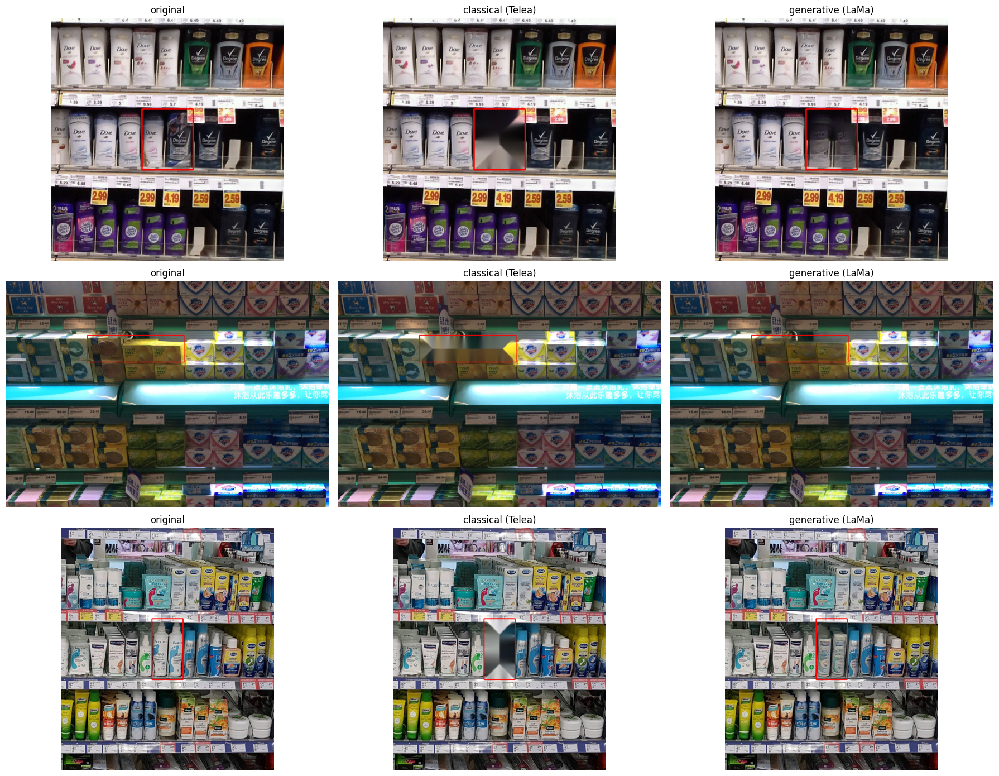

In [15]:
fig, ax = plt.subplots(3, 3, figsize=(18, 14))
for r, rec in enumerate(test_syn[:3]):
    im = cv2.imread(rec["photo"]); mask = gap_mask(im.shape, rec["gap"]); x1, y1, x2, y2 = rec["gap"].astype(int)
    pad = int(1.5 * max(x2 - x1, y2 - y1))
    for c, (title, img) in enumerate([("original", im)] + [(name, fill(im, mask)) for name, fill in METHODS.items()]):
        img = cv2.rectangle(img.copy(), (x1, y1), (x2, y2), (0, 0, 255), 3)
        ax[r, c].imshow(img[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad, ::-1]); ax[r, c].set_title(title); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

**After: what we saw.** Classical fill smears neighbouring colours into a blurry X-shaped patch: obviously fake, but clearly empty. LaMa does the opposite of what we hoped: it continues the pattern around the hole, and on a shelf that pattern is products, so it paints faded 'ghost' products back in. LaMa was trained on general photos (scenes, buildings) where continuing the surroundings is the right answer; on a crowded shelf the right answer is an empty shelf, which it has rarely seen.

### Step 4.3 Tune the gap finder on synthetic validation shelves

**Before we run this.** What counts as a gap is a business rule, not something to fit to the data: empty space at least
half a product wide (`MIN_GAP` = 0.5, as in the labelling guide). What we tune is `tol`: how far the bottom edges of
products may differ before a new shelf row starts (in product heights). Too small splits one shelf into several rows; too
large merges shelves. For each value we measure *recall* (share of the erased gaps found) and *false gaps per photo*
(anything else flagged; SKU-110K shelves are mostly full, so these are mostly false alarms, though a few may be real gaps
nobody labelled). Each filler gets its own best `tol`, so neither is judged with settings tuned for the other.

In [16]:
def gap_scores(syn, key, tol, min_gap=MIN_GAP):
    """Gap-finder scores on synthetic shelves. key = a filler name, or "original" (nothing erased: every gap is extra)."""
    hits = extra = 0
    for rec in syn:
        gaps = find_gaps(rec[key][0], min_gap, tol)[0]
        found, other = match_gaps(gaps, rec["gap"]) if key != "original" else (False, len(gaps))
        hits += found; extra += other
    p, r = hits / max(hits + extra, 1), hits / len(syn)
    return {"recall": r, "precision": p, "F1": 2 * p * r / max(p + r, 1e-9), "false gaps per photo": extra / len(syn)}

grid = pd.DataFrame([{"filler": name, "tol": t, **gap_scores(val_syn, name, t)}
                     for name in METHODS for t in (0.4, 0.5, 0.6, 0.75, 0.9, 1.0)])
TOL = {name: float(g.loc[g.F1.idxmax(), "tol"]) for name, g in grid.groupby("filler")}
print("chosen tol per filler:", TOL)
grid.set_index(["filler", "tol"]).round(3)

chosen tol per filler: {'classical (Telea)': 0.75, 'generative (LaMa)': 0.6}


recall  precision     F1  false gaps per photo
filler            tol                                                 
classical (Telea) 0.40   0.883      0.065  0.120                12.800
                  0.50   0.867      0.071  0.130                11.417
                  0.60   0.833      0.077  0.142                 9.933
                  0.75   0.600      0.080  0.142                 6.867
                  0.90   0.383      0.072  0.122                 4.917
                  1.00   0.333      0.074  0.121                 4.167
generative (LaMa) 0.40   0.150      0.012  0.021                12.817
                  0.50   0.133      0.011  0.021                11.550
                  0.60   0.133      0.013  0.024                10.117
                  0.75   0.083      0.011  0.020                 7.183
                  0.90   0.033      0.006  0.011                 5.183
                  1.00   0.000      0.000  0.000                 4.417

**After: what we saw.** Classical fills: the gap finder recovers 83% of the erased gaps at tol 0.6, and the best F1 is at tol 0.75 (recall 60%). LaMa fills: at most 15% recovered at any setting, because the detector sees products in the repainted hole. Larger `tol` merges shelf rows and lowers false gaps (12.8 to 4.2 per photo) at the cost of recall, so the row setting is the main lever on false alarms.

### Step 4.4 Did the generative filler matter? (test shelves)

**Before we run this.** The gap finder on 100 synthetic test shelves, once per filler, each with its own tuned `tol`. *Recall*: erased gaps found.
*False gaps per photo*: anything else flagged; the first row (original photos, nothing erased) is the noise level of the
gap finder on its own. *Ghost product in hole*: share of photos where the detector sees a product inside the filled area,
which would hide the gap. *Other products still found*: detector recall on the products we did not erase, to check the
fill did not damage its neighbours.

In [17]:
rows = [{"filler": "original (nothing erased)", **gap_scores(test_syn, "original", TOL["generative (LaMa)"]),
         "recall": np.nan, "precision": np.nan, "F1": np.nan}]
for name in METHODS:
    rows.append({"filler": name, "tol": TOL[name], **gap_scores(test_syn, name, TOL[name]),
                 "ghost product in hole": np.mean([any(covered(b, rec["gap"]) >= 0.5 for b in rec[name][0]) for rec in test_syn]),
                 "other products still found": precision_recall({rec["photo"]: rec[name] for rec in test_syn},
                                                                {rec["photo"]: rec["kept"] for rec in test_syn}, CONF)[1]})
pd.DataFrame(rows).set_index("filler").round(3)

,recall,precision,F1,false gaps per photo,tol,ghost product in hole,other products still found
filler,,,,,,,
original (nothing erased),NaN,NaN,NaN,10.81,NaN,NaN,NaN
classical (Telea),0.56,0.064,0.115,8.20,0.75,0.03,0.861
generative (LaMa),0.05,0.005,0.008,10.81,0.60,0.83,0.862


**After: what we saw.** **The generative filler made the test harder, not better.** On 100 test shelves: classical fill, 56% of erased gaps found; LaMa, 5%. The reason is the *ghost product* column: in 83% of LaMa fills the detector finds a product inside the hole (classical 3%). Neither fill damaged the neighbouring products (86% still found, the same as on untouched photos). The gap finder also flags about 8–11 gaps per photo that are not the erased one; on SKU-110K's mostly full shelves these are mainly false alarms, largely where the detector missed a product. **Conclusion for the report:** off-the-shelf inpainting reproduces products on dense shelves, so a generic generative model cannot create realistic empty shelves here; it needs guidance towards 'empty' (for example a text-guided diffusion inpainter prompted with 'empty shelf'). This is a measured negative result, not a failure of the code.

## Part 5 · Results on real shelf photos

**Before we run this.** The 40 photos we took in local stores, uploaded to Google Drive at `MyDrive/shelfwatch/own_shelves/`.
Each photo is checked twice. *As it is:* the app's own analysis (`pipeline.analyse`, the code the Streamlit app runs):
products, gaps, people blurred. *With a planted gap:* LaMa erases 1–3 neighbouring products the model found, and we check
whether the analysis then finds that new gap. The model knows one class, "product": it reports **where** a gap is (shelf
row, position, width in products), not **which brand** is missing.

In [18]:
from pipeline import analyse, draw_result
OWN_SHELVES = "/content/drive/MyDrive/shelfwatch/own_shelves"
photos = sorted(os.path.join(OWN_SHELVES, f) for f in os.listdir(OWN_SHELVES) if f.lower().endswith((".jpg", ".jpeg", ".png")))
people = ProductDetector(YOLO("yolo11n.pt").export(format="onnx"), size=640)   # COCO model, used only to blur people
lama, tol, rng = METHODS["generative (LaMa)"], TOL["generative (LaMa)"], np.random.default_rng(SEED)

summary = []
for p in photos:
    im = cv2.imread(p)
    before = analyse(im, det, people, tol)                                   # as it is
    row = {"photo": os.path.basename(p), "products found": len(before["boxes"]), "gaps found": len(before["gaps"]),
           "people blurred": before["people"], "warnings": len(before["problems"])}
    plan = plan_gap(before["boxes"], rng)
    if plan is not None:                                                     # with a planted gap
        gap, kept = plan
        after = analyse(lama(im, gap_mask(im.shape, gap)), det, people, tol)
        row.update({"products erased": len(before["boxes"]) - len(kept), "products found after": len(after["boxes"]),
                    "planted gap found": bool(match_gaps(after["gaps"], gap)[0])})
        fig, ax = plt.subplots(1, 2, figsize=(18, 8))
        ax[0].imshow(cv2.cvtColor(draw_result(before["image"], before["boxes"], before["gaps"]), cv2.COLOR_BGR2RGB))
        shown = cv2.rectangle(draw_result(after["image"], after["boxes"], after["gaps"]), tuple(gap[:2].astype(int)),
                              tuple(gap[2:].astype(int)), (0, 255, 255), 6)
        ax[1].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB))
        ax[0].set_title(f"as it is: {row['products found']} products, {row['gaps found']} gaps")
        ax[1].set_title(f"LaMa erased {row['products erased']} (yellow): planted gap found = {row['planted gap found']}")
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.show()
    summary.append(row)
pd.DataFrame(summary).set_index("photo")

(Photos of the local stores are not published in this public notebook: the stores allowed photography, not publication.)


Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from 'yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 10 packages in 226ms
Prepared 3 packages in 204ms
Installed 3 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.7s, saved as 'yolo11n.onnx' (10.2 MB)

Export complete (3.1s)
Results saved to /content/yolo11n.onnx
Predict:         yolo predict task=detect model=yolo11n.onnx imgsz=640 
Vali

,products found,gaps found,people blurred,warnings,products erased,products found after,planted gap found
photo,,,,,,,
shelf_01.png,61,13,0,0,2.0,61.0,False
shelf_02.png,53,12,0,0,1.0,53.0,False
shelf_03.png,39,12,1,0,1.0,38.0,True
shelf_04.png,40,4,0,0,NaN,NaN,NaN
shelf_05.png,36,6,2,1,2.0,34.0,False
shelf_06.png,41,2,0,0,NaN,NaN,NaN
shelf_07.png,49,1,1,0,NaN,NaN,NaN
shelf_08.png,47,3,0,0,NaN,NaN,NaN
shelf_09.png,61,11,0,0,3.0,60.0,False


**After: what we saw.** 
**As it is:** on all 40 store photos the app finds products and gaps in under a second each, blurs every shopper it sees,
and warns on 5 photos (people hiding the shelf, or the model unsure on flat chocolate bars). On shelf_01 it marks 13 gaps,
and they match the empty shelf space visible in the photo. **With a planted gap:** LaMa's planted gap was found in only 3
of 27 photos, for the same reason as Part 4: LaMa repaints ghost products (shelf_01, yellow box: two faded jars), and the
detector counts them. The products-found count barely changes after erasing, which confirms it.

### Step 5.2 The app's gaps vs gaps drawn by hand

**Before we run this.** The real-world test. On all 40 photos a person drew every gap by hand, following the labelling
guide (empty space at least half a product wide), without seeing the app's gap output. A gap counts as found when the app
marks the same stretch of the same shelf (the matching rule of Part 4). *Recall*: share of hand-drawn gaps the app finds.
*Precision*: share of the app's gaps that a person also marked. Some 'wrong' app gaps may be real gaps the labeller left
out when unsure, so precision is a lower bound. The row setting `tol` is shown for three values, none chosen on these photos.

In [ ]:
def hand_gaps(photo, W, H):
    a = np.loadtxt(os.path.join(OWN_SHELVES, "labels", os.path.splitext(os.path.basename(photo))[0] + ".txt"), ndmin=2)
    a = a[a[:, 0] == 1]                                               # class 1 = gap
    cx, cy, w, h = a[:, 1] * W, a[:, 2] * H, a[:, 3] * W, a[:, 4] * H
    return np.c_[cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]

def same_stretch(p, t):
    return min(p[2], t[2]) - max(p[0], t[0]) >= 0.5 * max(p[2] - p[0], t[2] - t[0]) and min(p[3], t[3]) > max(p[1], t[1])

rows = []
for t in (0.5, 0.6, 0.75):
    res = {}
    for p in photos:
        im = cv2.imread(p); truth = hand_gaps(p, im.shape[1], im.shape[0]); g = analyse(im, det, people, t)["gaps"]
        res[os.path.basename(p)] = (len(truth), sum(any(same_stretch(x, y) for x in g) for y in truth),
                                    len(g), sum(any(same_stretch(x, y) for y in truth) for x in g))
    for group, keys in [("all 40", list(res)), ("shelf_01-31", [k for k in res if k < "shelf_32"]),
                        ("chocolate shelves 32-40", [k for k in res if k >= "shelf_32"])]:
        T, F, P, C = (sum(res[k][i] for k in keys) for i in range(4)); r, pr = F / max(T, 1), C / max(P, 1)
        rows.append({"tol": t, "photos": group, "hand-drawn gaps": T, "found": F, "recall": r,
                     "app gaps": P, "also hand-drawn": C, "precision": pr, "F1": 2 * pr * r / max(pr + r, 1e-9)})
pd.DataFrame(rows).set_index(["tol", "photos"]).round(2)

hand-drawn gaps  found  recall  app gaps  also hand-drawn  precision    F1
tol  photos                                                                                             
0.50 all 40                               108     87    0.81       310               93       0.30  0.44
     shelf_01-31                          104     84    0.81       224               88       0.39  0.53
     chocolate shelves 32-40                4      3    0.75        86                5       0.06  0.11
0.60 all 40                               108     85    0.79       285               89       0.31  0.45
     shelf_01-31                          104     82    0.79       203               84       0.41  0.54
     chocolate shelves 32-40                4      3    0.75        82                5       0.06  0.11
0.75 all 40                               108     80    0.74       238               84       0.35  0.48
     shelf_01-31                          104     77    0.74       173               79       0.46  0.56
     chocolate shelves 32-40                4      3    0.75        65                5       0.08  0.14

**After: what we saw.** 
**The app finds about 8 in 10 of the gaps a person sees** (recall 0.81 at the app's setting `tol` 0.5; 0.74 at 0.75).
**But it also reports too many gaps:** only 30–35% of its gaps were also drawn by hand (39–46% on shelf_01–31). On the
chocolate shelves (shelf_32–40) precision falls to 6–8%: the model misses flat, lying bars, and every missed bar looks like
empty shelf. A larger `tol` trades a little recall for fewer false gaps. **Next improvement:** before reporting a gap, check
that the space really looks empty (an empty shelf back has few edges; a missed product has many), and retrain with flat
products in mind.

### Step 5.3 Cutting false gaps: does the space really look empty?

**Before we run this.** Step 5.2 showed the main weakness: too many false gaps, mostly where the detector missed a product.
A real gap shows the plain back of the shelf; a missed product still shows print and outlines. So for each gap we measure
its share of edge pixels (Canny, Lecture 2) relative to a typical product in the same photo ("busyness"). Gaps below a
cut-off are listed as *empty shelf: restock*; the rest as *check: may be a missed product*, for a person to look at.
To keep the test honest, the cut-off is chosen on the 20 odd-numbered photos and the result is reported on the 20
even-numbered ones, which the tuning never saw.

In [ ]:
from pipeline import busyness, EMPTY_CUT
cache = {}                                                     # photo -> (hand-drawn gaps, app gaps, busyness of each)
for p in photos:
    im = cv2.imread(p); r = analyse(im, det, people)
    cache[os.path.basename(p)] = (hand_gaps(p, im.shape[1], im.shape[0]), r["gaps"], busyness(im, r["gaps"], r["boxes"]))

def gap_f1(names, cut):
    T = F = P = C = 0
    for n in names:
        truth, gaps, busy = cache[n]; keep = gaps[busy < cut]
        T += len(truth); P += len(keep); F += sum(any(same_stretch(g, t) for g in keep) for t in truth)
        C += sum(any(same_stretch(g, t) for t in truth) for g in keep)
    r, pr = F / max(T, 1), C / max(P, 1)
    return {"recall": r, "precision": pr, "F1": 2 * pr * r / max(pr + r, 1e-9), "gaps listed": P}

odd = [n for n in cache if int(n[6:8]) % 2 == 1]; even = [n for n in cache if int(n[6:8]) % 2 == 0]
tune = pd.DataFrame([{"cut-off": c, **gap_f1(odd, c)} for c in (0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, np.inf)]).set_index("cut-off")
best = tune.F1.idxmax(); print("tuned on odd photos:\n", tune.round(2).to_string(), f"\nchosen cut-off {best} (pipeline.EMPTY_CUT = {EMPTY_CUT})")
pd.DataFrame([{"photos": label, "check": name, **gap_f1(sel, cut)}
              for label, sel in [("even (test, 20)", even), ("all 40", list(cache))]
              for name, cut in [("without", np.inf), ("with", best)]]).set_index(["photos", "check"]).round(2)

tuned on odd photos:
          recall  precision    F1  gaps listed
cut-off                                      
0.20       0.63       0.55  0.59           67
0.25       0.66       0.54  0.59           76
0.30       0.68       0.53  0.60           81
0.35       0.69       0.51  0.59           87
0.40       0.69       0.49  0.57           90
0.50       0.71       0.45  0.55           99
0.60       0.75       0.42  0.53          113
inf        0.76       0.31  0.44          158 
chosen cut-off 0.3 (pipeline.EMPTY_CUT = 0.3)

recall  precision    F1  gaps listed
photos          check                                        
even (test, 20) without    0.86       0.29  0.43          152
                with       0.65       0.55  0.60           60
all 40          without    0.81       0.30  0.44          310
                with       0.67       0.54  0.60          141

**After: what we saw.** Real gaps and false gaps really do look different: on these photos a real gap has a median of
about 12% of a typical product's edges, a false gap about 50%. The best cut-off on the odd photos is 0.3. **On the
20 unseen even photos precision rises from 0.29 to 0.55**
(the red list is right about twice as often), F1 from 0.43 to 0.60,
and the number of gaps listed falls from 152 to 60.
The price is recall: 0.86 to 0.65. That is why the app does
not delete the busy gaps: it shows them in orange as "check", so a person still sees every candidate (human in the loop),
while the red restock list becomes trustworthy. The chocolate shelves remain the weak spot: flat bars the detector misses
still look busy, so they mostly land in "check", which is the right place for them.

**Next.** Guide the generative fill towards empty shelf (text-guided inpainting) and re-run Part 4; retrain the detector
with flat, lying products so fewer products are missed in the first place.